## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

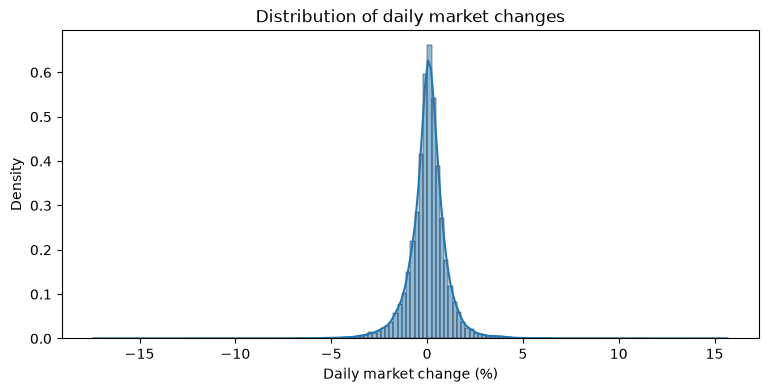

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

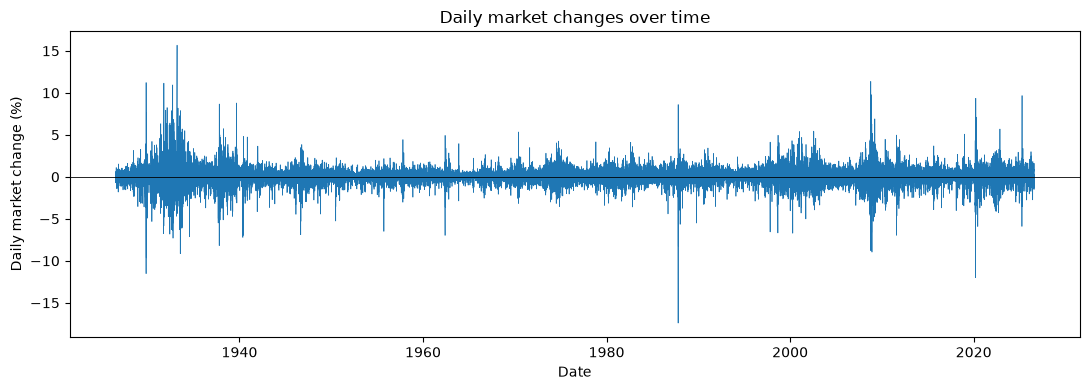

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

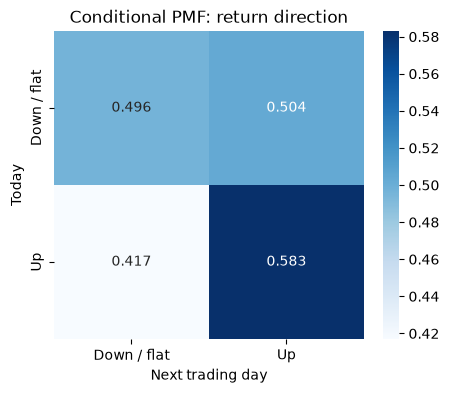

In [28]:
conditional_direction = pd.crosstab(
    df['direction_t'],
    df['direction_tp1'],
    normalize='index'
)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    conditional_direction,
    annot=True,
    fmt='.3f',
    cmap='Blues',
    ax=ax
)
ax.set(
    xlabel='Next trading day',
    ylabel='Today',
    title='Conditional PMF: return direction'
)
plt.show()

In [6]:
# make a categorical column "direction_t" 
direction_categories = ['Down / flat', 'Up']
np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat')

df['direction_t'] = pd.Categorical(
    np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat'),
    categories=direction_categories,
    ordered=True,
)

In [7]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df['direction_t'].shift(-1)

In [8]:
df[["direction_t","direction_tp1"]]

,direction_t,direction_tp1
0,Up,Up
1,Up,Up
2,Up,Up
3,Up,Up
4,Up,Down / flat
...,...,...
26291,Up,Up
26292,Up,Down / flat
26293,Down / flat,Up
26294,Up,Up


In [9]:
pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = True, margins = True)

direction_tp1,Down / flat,Up,All
direction_t,,,
Down / flat,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


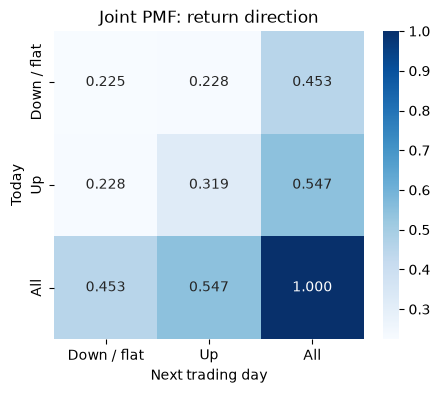

In [10]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = True, margins = True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

In [11]:
# Plot the conditional PMF
pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = 'index')

direction_tp1,Down / flat,Up
direction_t,,
Down / flat,0.496221,0.503779
Up,0.416974,0.583026


<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

</div>

ANSWER:

Transitions to an Up day are more common than transitions to a Down/flat day. The next trading day is Up approximately 54.71% of the time and Down/flat approximately 45.29% of the time.

You are more likely to transition to an Up day from an Up day. The probability is approximately 58.30% after an Up day, compared with 50.38% after a Down/flat day.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- Subtract the marginal PMF of tomorrow's state from each row of the conditional PMF, and plot the result as a heatmap. If tomorrow's state were independent of today's, every row of the conditional PMF would equal this marginal. Which transitions are more likely than independence predicts, and which are less likely? Does knowing today's state change the forecast for tomorrow?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [13]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['return_bin'] = pd.cut(df['market_return_pct'], bins = [-np.inf, -1, -0.1, 0.1,1, np.inf], labels = return_categories)


In [14]:
df['return_bin'].value_counts()

return_bin
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

In [15]:
#make y_t and y_tp1 columns for the return bins
df['y_t'] = df['return_bin']
df['y_tp1'] = df['return_bin'].shift(-1)

In [16]:
pd.crosstab(df['y_t'], df['y_tp1'], normalize = True, margins = True)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)
- Which are the most or least common?
  
  </div>

ANSWER:

Large loss: 2,759 days.
Small loss: 7,452 days.
Near zero: 3,441 days.
Small gain: 9,785 days.
Large gain: 2,859 days.

Small gain is the most common category, with 9,785 days.
Large loss is the least common category, with 2,759 days.

In [ ]:
#joint PMF with marginals

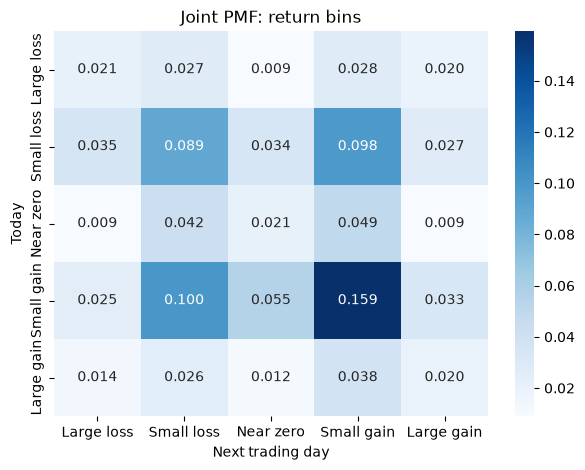

In [17]:
#joint PMF with marginals
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1'], normalize=True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Which transitions are most likely to occur? 

</div>

ANSWER:

The most likely transition is Small gain → Small gain, accounting
for approximately 15.94% of all consecutive trading-day pairs.

The next most likely transitions are Small gain → Small loss
(10.01%) and Small loss → Small gain (9.78%).

In [ ]:
#conditional PMF 

In [18]:
#conditional PMF 
pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely? 
- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 
- Is it relatively easy or difficult to predict the next state?
</div>

ANSWER:

For every current state, the two most likely next states are
Small gain followed by Small loss:

• Large loss: Small gain (26.50%), Small loss (25.92%).
• Small loss: Small gain (34.50%), Small loss (31.28%).
• Near zero: Small gain (37.69%), Small loss (32.08%).
• Small gain: Small gain (42.85%), Small loss (26.89%).
• Large gain: Small gain (34.77%), Small loss (23.47%).

None of the rows is uniform. The Large loss row is closest to
20% across all five outcomes, although Near zero is only 8.63%.
The Small gain row differs most strongly, with probabilities
ranging from 6.72% to 42.85%. The remaining rows also favor
small gains and small losses over other outcomes.

Predicting the next state is relatively difficult. Although
Small gain is the most likely outcome in every row, its
probability remains below 50%, so substantial uncertainty remains.

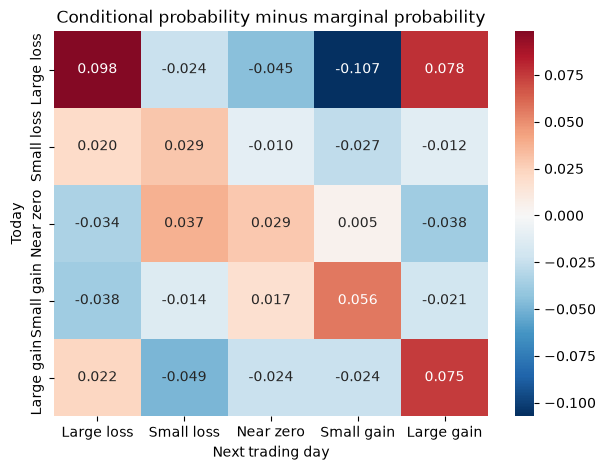

In [19]:
# marginal PMF of tomorrow's state: sum the joint PMF (without margins) down each column
next_state_pmf = next_state_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True).sum(axis=0)
next_state_pmf

conditional = pd.crosstab(df['y_t'], df['y_tp1'], normalize="index")
# subtract it from each row of the conditional PMF and plot as a heatmap
# hint: use .sub(next_state_pmf, axis='columns'), and a diverging colormap such as cmap='RdBu_r' with center=0
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(conditional.sub(next_state_pmf, axis='columns'),
            annot=True, fmt='.3f', center=0, cmap='RdBu_r', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today',
       title='Conditional probability minus marginal probability')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?
- Does knowing today's state change the forecast for tomorrow?
- How is this comparison different from comparing each row to a uniform PMF with probability .2?
</div>

ANSWER:

Compared with independence, the more likely next states are:

• After Large loss: Large loss and Large gain.
• After Small loss: Large loss and Small loss.
• After Near zero: Small loss, Near zero, and Small gain.
• After Small gain: Near zero and Small gain.
• After Large gain: Large loss and Large gain.

All other transitions are less likely than independence predicts.

Knowing today's state changes tomorrow's forecast. Large changes
today tend to increase the chance of another large change tomorrow,
in either direction.

Comparing each row with tomorrow's marginal PMF accounts for
the actual overall frequency of each category. Independence
means those probabilities do not change with today's state.
Comparing with 0.2 instead assumes all five categories are
equally likely, which they are not.

In [21]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
# use groupby and describe/mean to get the conditional expectation of the next day's return given today's return bin y_t
df.groupby("y_t")["market_return_pct_tp1"].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


/var/folders/43/f8z3kwjs27j1ztlt_wxk3q140000gp/T/ipykernel_97052/817726577.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("y_t")["market_return_pct_tp1"].describe()

<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow? 
- How do the min and max values for tomorrow vary across states? 
- Which states have the highest standard deviation for tomorrow's percent returns? 
- Describe any patterns in the volatility you notice.
</div>


ANSWER:

Tomorrow's expected return depends on today's category:

• Large loss: −0.0383%.
• Small loss: −0.0438%.
• Near zero: 0.0150%.
• Small gain: 0.1068%.
• Large gain: 0.1631%.

Tomorrow's observed minimum and maximum returns are:

• After Large loss: −17.41% to 11.22%.
• After Small loss: −11.23% to 11.36%.
• After Near zero: −8.19% to 5.49%.
• After Small gain: −8.25% to 8.67%.
• After Large gain: −12.00% to 15.67%.

Tomorrow's standard deviation is highest after a Large loss
(1.7206 percentage points), followed by a Large gain (1.3841).
It is lower after Small loss (1.0095), Small gain (0.8322),
and Near zero (0.8261).

This suggests volatility clustering: large changes today tend
to be followed by greater variability tomorrow. The average
returns are small compared with the standard deviations, so
the actual next-day return remains uncertain.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [23]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

y_t,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21
Trading days,1255,1253,1286,1280,1230,1226,1371,1206,1198,1331,...,1223,1294,1223,1310,1193,1211,1283,1225,1250,1238


In [25]:
#joint PMF with marginals for the 21 quantile bins + plot as heatmap
quantile_joint = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize=True, margins = False
)

<Axes: xlabel='y_tp1', ylabel='y_t'>

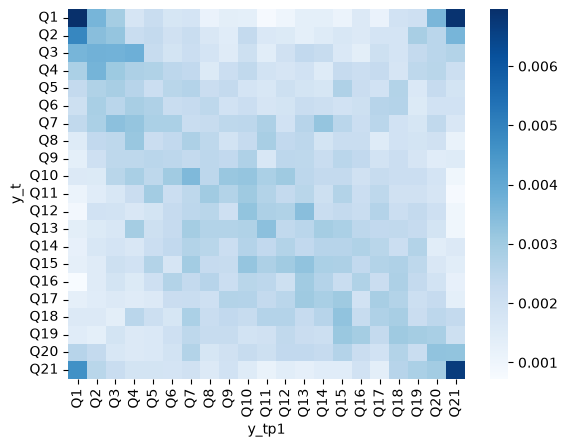

In [26]:
sns.heatmap(quantile_joint, cmap='Blues')

In [ ]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.

<Axes: xlabel='y_tp1', ylabel='y_t'>

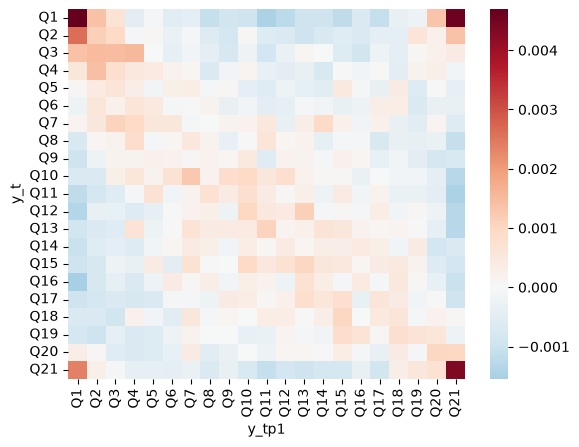

In [27]:
sns.heatmap(quantile_joint - 1/bins**2, cmap='RdBu_r', center=0)

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

ANSWER:

The four corners show positive deviations from the uniform
joint probability of 1/21². This means pairs of extreme returns
occur more often than the uniform benchmark predicts.

Q1 contains the lowest returns, and Q21 contains the highest.
The red corners show that extreme returns today tend to be
followed by extreme returns tomorrow, in either direction.
This suggests volatility clustering.

Blue areas show pairs that occur less often than the uniform
benchmark predicts. The pattern is not uniformly random,
but it does not make tomorrow's direction certain.

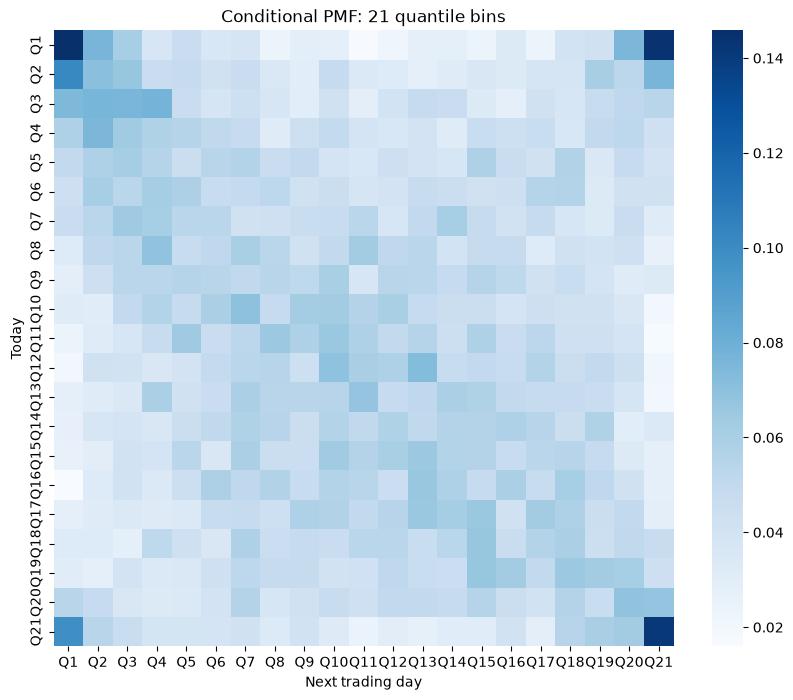

In [29]:
quantile_conditional = pd.crosstab(
    df['y_t'],
    df['y_tp1'],
    normalize='index'
)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(quantile_conditional, cmap='Blues', ax=ax)
ax.set(
    xlabel='Next trading day',
    ylabel='Today',
    title='Conditional PMF: 21 quantile bins'
)
plt.show()

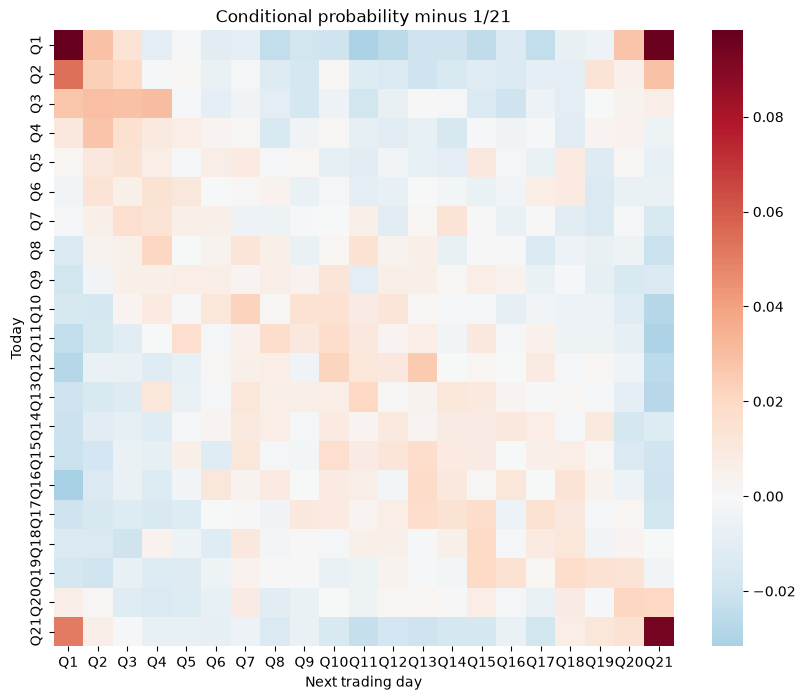

In [30]:
# Subtract the uniform conditional probability of 1/21
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    quantile_conditional - 1/21,
    cmap='RdBu_r',
    center=0,
    ax=ax
)
ax.set(
    xlabel='Next trading day',
    ylabel='Today',
    title='Conditional probability minus 1/21'
)
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

ANSWER:

Yes. The conditional heatmap shows higher probabilities in
the corners, indicating that extreme returns today increase
the likelihood of extreme returns tomorrow, in either direction.

After subtracting 1/21 (approximately 0.0476), red cells show
transitions more likely than the uniform benchmark, while
blue cells show transitions less likely than that benchmark.

The red corners suggest volatility clustering. Middle rows
generally favor middle bins over the extreme bins, suggesting
that calmer days tend to be followed by calmer days.

Today's return provides some information about tomorrow's
volatility, but tomorrow's exact return and direction remain
uncertain.

In [31]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)

quantile_summary = (
    df.groupby('y_t', observed=True)['market_return_pct_tp1']
    .agg(['min', 'mean', 'max'])
    .reindex(labels)
)

quantile_summary

,min,mean,max
y_t,,,
Q1,-17.41,-0.013713,11.22
Q2,-7.36,-0.076712,6.36
Q3,-8.79,-0.097084,11.36
Q4,-8.28,-0.058594,6.16
Q5,-6.89,-0.024211,4.56
Q6,-11.23,-0.022692,6.37
Q7,-3.94,-0.030241,7.37
Q8,-3.40,-0.014303,4.76
Q9,-6.00,0.025860,5.49


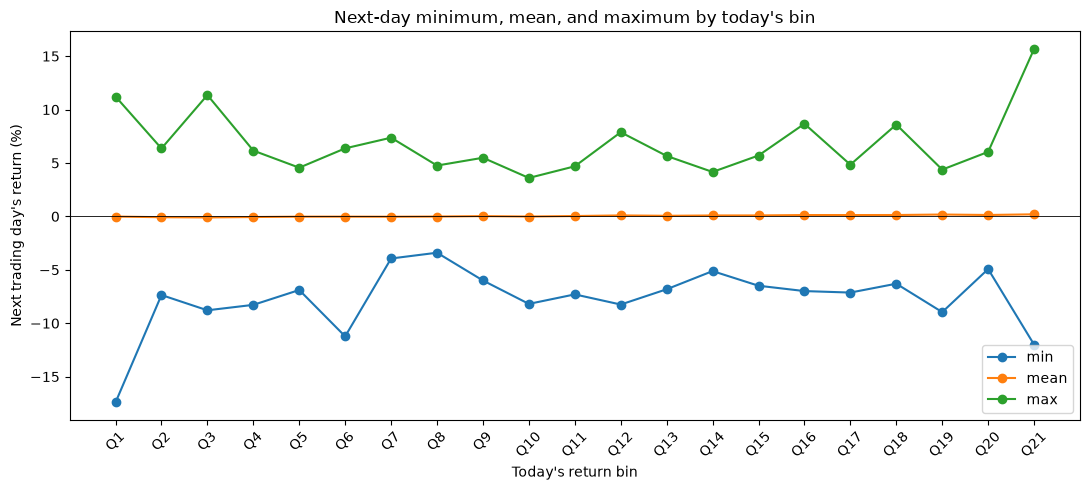

In [32]:
fig, ax = plt.subplots(figsize=(11, 5))

for statistic in ['min', 'mean', 'max']:
    ax.plot(
        quantile_summary.index,
        quantile_summary[statistic],
        marker='o',
        label=statistic
    )

ax.axhline(0, color='black', linewidth=0.6)
ax.set(
    xlabel="Today's return bin",
    ylabel="Next trading day's return (%)",
    title="Next-day minimum, mean, and maximum by today's bin"
)
ax.legend()
plt.xticks(rotation=45)
fig.tight_layout()
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

ANSWER:

The mean next-day return stays close to zero across all bins,
although it generally increases from slightly negative values
in the lower bins to positive values in the higher bins.

The widest observed ranges occur after extreme returns.
After Q1, tomorrow's returns range from −17.41% to 11.22%.
After Q21, they range from −12.00% to 15.67%. The middle
bins generally have narrower ranges, although the pattern
is irregular.

Every bin includes both positive and negative next-day returns.
The small means compared with the wide ranges show that
today's bin does not reliably determine tomorrow's return.

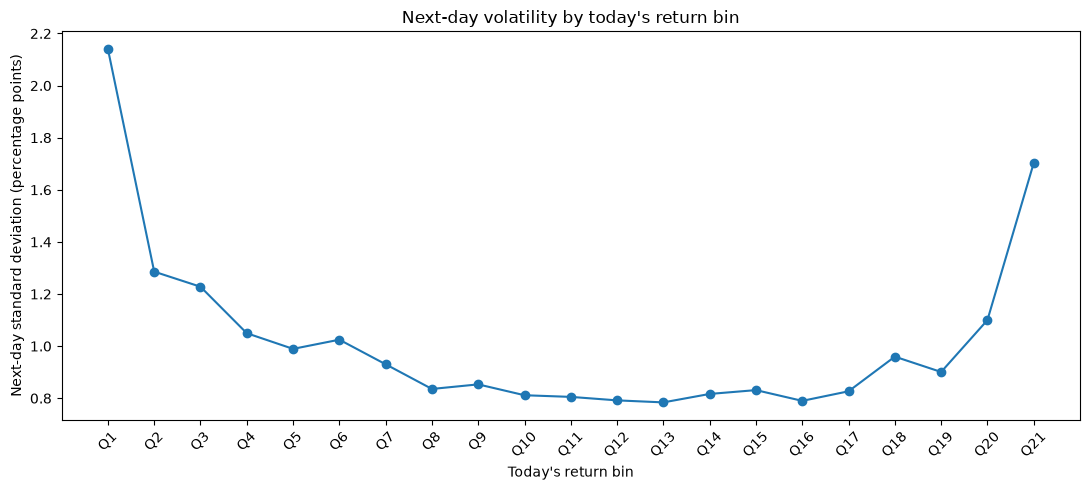

In [33]:
quantile_std = (
    df.groupby('y_t', observed=True)['market_return_pct_tp1']
    .std()
    .reindex(labels)
)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(quantile_std.index, quantile_std.values, marker='o')

ax.set(
    xlabel="Today's return bin",
    ylabel="Next-day standard deviation (percentage points)",
    title="Next-day volatility by today's return bin"
)

plt.xticks(rotation=45)
fig.tight_layout()
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

ANSWER:

The graph forms a U-shape, or valley. Tomorrow's standard
deviation is higher after extreme returns in the lowest and
highest bins, and lower after returns in the middle bins.

This suggests volatility clustering: large movements tend
to be followed by greater volatility, while calmer days tend
to be followed by lower volatility. This helps predict the
size of tomorrow's fluctuations, but not necessarily whether
the market will rise or fall.

<div class='alert alert-info'><b>Answer the following:</b>

How easy is it to predict the market?
</div>

ANSWER:

Predicting the market's exact next-day return or direction
is difficult. Today's return changes the probabilities of
tomorrow's outcomes, but substantial uncertainty remains.

The clearest pattern is volatility clustering. Extreme
returns today tend to be followed by greater variability
tomorrow. Today's return therefore provides useful information
about volatility without making tomorrow's return certain.